In [ ]:
print("HARSHAVARTHAN SB 24BAD033")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import urllib.request
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.optimizers import Adam

HARSHAVARTHAN SB 24BAD033


In [ ]:
print("HARSHAVARTHAN SB 24BAD033")
# ---------------- PART A : DATASET PREPARATION ----------------

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(url).read().decode('utf-8')

print("Dataset: Tiny Shakespeare")
print(f"Total characters: {len(text)}")
print("\nFirst 500 characters:")
print(text[:500])

text = text.lower()
print("\nText converted to lowercase")

words = text.split()
print(f"Total number of words: {len(words)}")
print(f"First 20 words: {words[:20]}")

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

vocab_size = len(tokenizer.word_index) + 1
print(f"\nVocabulary size: {vocab_size}")

word_index = tokenizer.word_index
print("\nSample word-to-index mappings:")
for word, idx in list(word_index.items())[:10]:
    print(f"  '{word}' -> {idx}")

sequences = []
encoded = tokenizer.texts_to_sequences([text])[0]

seq_length = 10

for i in range(seq_length, len(encoded)):
    seq = encoded[i - seq_length : i + 1]
    sequences.append(seq)

sequences = np.array(sequences)
print(f"\nTotal sequences generated: {len(sequences)}")
print(f"Sequence shape: {sequences.shape}")

sequences = pad_sequences(sequences, maxlen=seq_length + 1, padding='pre')
print(f"Padded sequence shape: {sequences.shape}")

X = sequences[:, :-1]
y = sequences[:, -1]

print(f"\nInput shape (X): {X.shape}")
print(f"Output shape (y): {y.shape}")

split = int(0.8 * len(X))

X_train = X[:split]
y_train = y[:split]
X_val = X[split:]
y_val = y[split:]

print(f"\nTraining samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")

HARSHAVARTHAN SB 24BAD033
Dataset: Tiny Shakespeare
Total characters: 1115394

First 500 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor

Text converted to lowercase
Total number of words: 202651
First 20 words: ['first', 'citizen:', 'before', 'we', 'proceed', 'any', 'further,', 'hear', 'me', 'speak.', 'all:', 'speak,', 'speak.', 'first', 'citizen:', 'you', 'are', 'all', 'resolved', 'rather']

Vocabulary size: 12633

Sample word-to-index mappings:
  'the' -> 1
  'and' -> 2
  'to' -> 3
  'i' -> 4
  'of' -> 5
  'you' -> 6
  'my' ->

In [ ]:
print("HARSHAVARTHAN SB 24BAD033")
# ---------------- PART B : IMPLEMENTING THE RNN MODEL ----------------

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=seq_length),
    SimpleRNN(128, return_sequences=False),
    Dense(vocab_size, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

print(f"\nInput sequence length: {seq_length}")
print(f"Vocabulary size: {vocab_size}")
print(f"Embedding dimension: 64")
print(f"RNN units: 128")

HARSHAVARTHAN SB 24BAD033


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Input sequence length: 10
Vocabulary size: 12633
Embedding dimension: 64
RNN units: 128


HARSHAVARTHAN SB 24BAD033
Epoch 1/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.0425 - loss: 6.7677 - val_accuracy: 0.0581 - val_loss: 6.8112
Epoch 2/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0781 - loss: 6.1650 - val_accuracy: 0.0750 - val_loss: 6.7361
Epoch 3/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0934 - loss: 5.8356 - val_accuracy: 0.0808 - val_loss: 6.7650
Epoch 4/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.1040 - loss: 5.5596 - val_accuracy: 0.0805 - val_loss: 6.8464
Epoch 5/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1136 - loss: 5.3068 - val_accuracy: 0.0806 - val_loss: 6.9458
Epoch 6/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.1257 - loss: 5.0738 - val_accuracy: 0.0779 - val_loss: 7.0688
Epoch 7/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1412 - loss: 4.8544 - val_accuracy: 0.0767 - val_loss: 7.1691
Epoch 8/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accurac

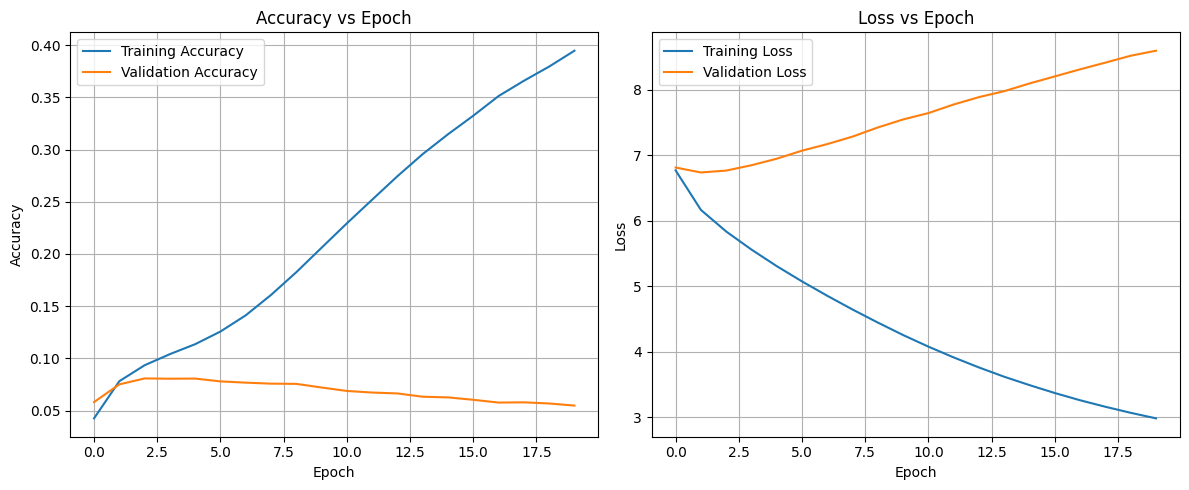

In [ ]:
print("HARSHAVARTHAN SB 24BAD033")
# ---------------- PART C : TRAINING AND EVALUATION ----------------

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=1
)

train_acc = history.history['accuracy'][-1]
val_acc = history.history['val_accuracy'][-1]
train_loss = history.history['loss'][-1]
val_loss = history.history['val_loss'][-1]

print("\nTRAINING RESULTS")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epoch')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss vs Epoch')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
print("HARSHAVARTHAN SB 24BAD033")
# ---------------- PART D : TEXT GENERATION ----------------

def generate_text(seed_text, num_words, model, tokenizer, seq_length):
    result = seed_text
    for _ in range(num_words):
        encoded = tokenizer.texts_to_sequences([result])[0]
        encoded = pad_sequences([encoded], maxlen=seq_length, padding='pre')
        pred = model.predict(encoded, verbose=0)
        pred_idx = np.argmax(pred, axis=1)[0]
        pred_word = ""
        for word, index in tokenizer.word_index.items():
            if index == pred_idx:
                pred_word = word
                break
        result = result + " " + pred_word
    return result

seeds = [
    "the king",
    "shall i",
    "to be or",
    "my lord",
    "what is"
]

print("TEXT GENERATION RESULTS")
print("=" * 60)

for i, seed in enumerate(seeds):
    generated = generate_text(seed, 20, model, tokenizer, seq_length)
    print(f"\nSeed {i + 1}: '{seed}'")
    print(f"Generated: {generated}")
    print("-" * 60)

print("\nOBSERVATION")
print("=" * 60)
print("The RNN model generates text by predicting the next word based on")
print("the context provided by the seed input. The generated text shows")
print("that the model has learned some sequential patterns from the")
print("Shakespeare dataset.")
print()
print("The coherence of generated text varies with different seed inputs.")
print("Seeds that contain common Shakespeare phrases tend to produce")
print("more contextually relevant output.")
print()
print("Limitations observed:")
print("- The Simple RNN struggles with long-range dependencies")
print("- Some generated sequences may become repetitive")
print("- The quality depends on vocabulary coverage and training data")

if train_acc > val_acc + 0.1:
    print("\nThe model shows some signs of overfitting.")
else:
    print("\nNo major overfitting observed from the training metrics.")

HARSHAVARTHAN SB 24BAD033
TEXT GENERATION RESULTS

Seed 1: 'the king'
Generated: the king of england and as i am sure of them and so i am sure you were you shall have you
------------------------------------------------------------

Seed 2: 'shall i'
Generated: shall i reap the issue of our brother and for his followers being a thousand times and settled by my death and
------------------------------------------------------------

Seed 3: 'to be or'
Generated: to be or else to be the matter to the people and therein we must be guiltless of the whole thing that you
------------------------------------------------------------

Seed 4: 'my lord'
Generated: my lord of bolingbroke as we will be a french lord and you say you have a man for him he would
------------------------------------------------------------

Seed 5: 'what is'
Generated: what is the gods and with the birth of his own self to greet my tongue i am a subject to thy
-----------------------------------------------------------